# **Smart Zoning : ATM Mobilis Project**

>  In this section, we focused only on PDVs from the **Algiers wilaya** to perform the following steps:
>
> 🔹 **Cluster the PDVs** while making sure that the workload is **balanced** between all zones.
>
> 🔹 **Update the zones** whenever a new PDV (or multiple PDVs) is **added** or **deleted** to the region.
>
> 🔹 **Recalculate zones** intelligently whenever there is a change in the list of PDVs.


#  Cluster the PDVs


In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import folium
from folium.plugins import MarkerCluster
import json

# Load PDV data for one Wilaya (e.g., Alger)
df = pd.read_csv("Wilaya_CSVs/Alger.csv")

# Load Wilaya polygons (GeoJSON file with shapes of all Wilayas)
wilayas_gdf = gpd.read_file("all-wilayas.geojson")

# Get the polygon for Algiers
alger_polygon = wilayas_gdf[wilayas_gdf['name'].str.lower() == "algiers"].geometry.values[0]

# Convert PDVs to shapely Points
df['geometry'] = df.apply(lambda row: Point(row['Longitude'], row['Latitude']), axis=1)

# Check which points are inside the Algiers polygon
df['inside'] = df['geometry'].apply(lambda point: point.within(alger_polygon))

# Filter to only valid PDVs that are inside the Algiers polygon
df_cleaned = df[df['inside']]

# Save the cleaned PDVs
df_cleaned.to_csv("cleaned_pdv_data.csv", index=False)

# Example of how to store rebalanced clusters (additionally if needed)
rebalanced_clusters = {
    # assuming you already have the structure for rebalanced_clusters
}

# Save the rebalanced clusters data
with open("rebalanced_clusters.json", "w", encoding="utf-8") as f:
    json.dump(rebalanced_clusters, f, ensure_ascii=False, indent=4)

# Visualize
map_center = [36.75, 3.06]
m = folium.Map(location=map_center, zoom_start=12)
cluster = MarkerCluster().add_to(m)

for _, row in df_cleaned.iterrows():
    folium.Marker([row['Latitude'], row['Longitude']], popup=row.get('Name', '')).add_to(cluster)

minx, miny, maxx, maxy = alger_polygon.bounds
wilaya_boundaries = (miny, maxy, minx, maxx)

# Just display the map
m


In [192]:
wilaya_boundaries

(36.5794268, 36.8208578, 2.7996922, 3.382583)

<>:11: SyntaxWarning: invalid escape sequence '\A'
<>:11: SyntaxWarning: invalid escape sequence '\A'
C:\Users\yousr\AppData\Local\Temp\ipykernel_22148\4194601862.py:11: SyntaxWarning: invalid escape sequence '\A'
  df = pd.read_csv('Wilaya_CSVs\Algiers_cleaned.csv')


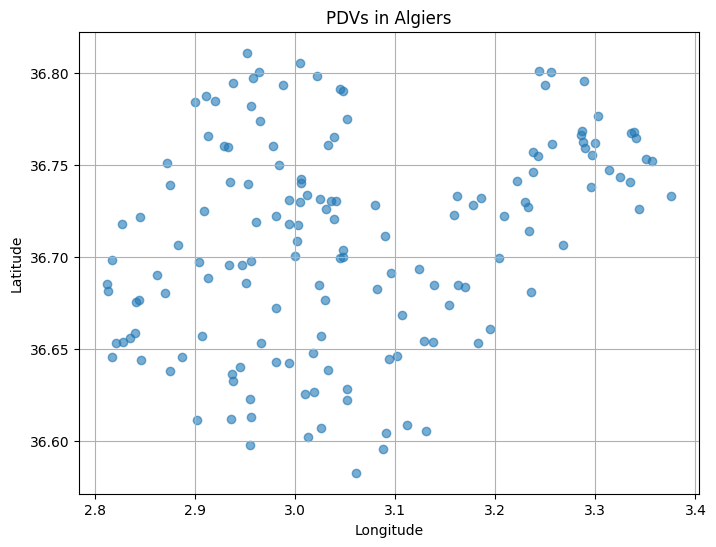

In [193]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
import folium
import numpy as np

from folium.plugins import MarkerCluster

# Load Algiers data
df = pd.read_csv('Wilaya_CSVs\Algiers_cleaned.csv')

# Basic scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df['Longitude'], df['Latitude'], alpha=0.6)
plt.title('PDVs in Algiers')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()



# Workload Calculation and Optimization Procedure

Our Goal is to design a **workload balancing system** across different geographic zones (clusters). Each zone contains **PDVs**, and we aim to distribute them in a balanced way, considering both **distance** and **quantity(number of pdvs)**.

---

## 1. Clustring PDVs
- We will use Kmean++ for a good initial cluster centroids. 
- K-Means++ chooses better starting points to make the algorithm more accurate and stable.

---

## 2. Workload Function Definition
We define the **workload** of a zone as:

$$
\text{Workload} = \alpha \times \text{AVG distance\_to\_centroid} + \beta \times \text{number\_of\_PDVs}
$$

- **α (alpha)**: weight assigned to the average distance of PDVs to the zone's centroid.
- **β (beta)**: weight assigned to the number of PDVs in the zone.

---

## 3. Regional Constraints
We adapt the values of α and β based on the region to reflect local priorities:

- **North Region**:  
  $$ \beta > \alpha $$  
  → Here, we care more about the number of PDVs than their distance.

- **South Region**:  
  $$ \alpha > \beta $$  
  → Here, distance is more critical than quantity.

These constraints allow us to customize the workload metric per region.

---

# Alpha Beta Intialization
>
> - We are trying to **find the best values** for two weights: **"alpha"** and **"beta"**.
>
> - **Alpha** controls how much we care about the *distance* between a PDV and its cluster center.
> - **Beta** controls how much we care about the *number of PDVs* in a cluster.
>
> - We test **20 values of alpha** from 0.1 to 2.
> - For each alpha, we test **20 values of beta** that are always **bigger than alpha**, up to 5.
>
> - For every combination of alpha and beta, we:
>   - Calculate the **workload** of each cluster using:  
>     `workload = alpha × avg_distance_To_centroid + beta × number_of_pdvs`
>   - Normalize the workloads to get percentages.
>   - Calculate the **variance** (how unbalanced the workloads are).
>
> - Our goal is to find the combination that gives the **lowest variance**,  
>   which means the clusters are more **balanced**.
>
> - We save the best alpha, beta, and workloads in a JSON file  
>   so we can use them later in our rebalancing algorithm.


KMeans++ Silhouette Score: 0.4092


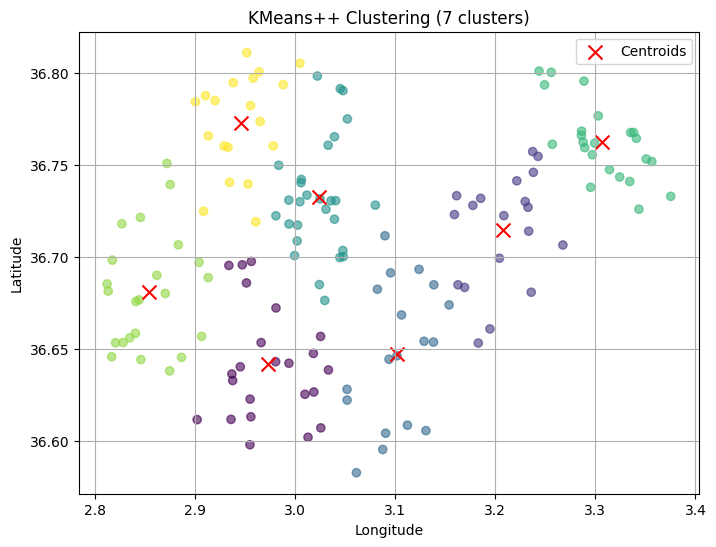

Average Workload is 14.285714285714288
     Cluster  AVG Distance (km)  Num of PDVs  Workload (%)    Status
0  Cluster 0           4.306567           23         15.12  Stressed
1  Cluster 1           4.040029           19         12.71   Relaxed
2  Cluster 2           4.478120           18         12.34   Relaxed
3  Cluster 3           3.503915           28         17.62  Stressed
4  Cluster 4           3.410332           23         14.71  Stressed
5  Cluster 5           4.043086           23         15.00  Stressed
6  Cluster 6           3.551712           19         12.49   Relaxed
7      TOTAL          27.333761          153         99.99          

 >> Data saved to 'initial_clusters.json' and 'best_workload_parameters.json'


In [194]:
import pandas as pd 
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import json
import math

# ------------------- [LOAD & CLEAN DATA] -------------------
df = pd.read_csv("Wilaya_CSVs/Algiers_cleaned.csv")
df.dropna(inplace=True)  

coords = df[['Latitude', 'Longitude']].to_numpy()
coords_rad = np.radians(coords)  

# ------------------- [KMEANS++ CLUSTERING] -------------------
kmeans = KMeans(n_clusters=7, init='k-means++', n_init=10, random_state=42)
kmeans.fit(coords_rad)
df['cluster'] = kmeans.labels_

# Evaluate performance
from sklearn.metrics import silhouette_score

# Calculate the Silhouette score
sil_score = silhouette_score(coords_rad, kmeans.labels_, metric='haversine')
print(f"KMeans++ Silhouette Score: {sil_score:.4f}")

# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(df['Longitude'], df['Latitude'], c=kmeans.labels_, cmap='viridis', alpha=0.6)
plt.scatter(np.degrees(kmeans.cluster_centers_[:, 1]),  # lon
            np.degrees(kmeans.cluster_centers_[:, 0]),  # lat
            marker='x', s=100, c='red', label='Centroids')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('KMeans++ Clustering (7 clusters)')
plt.legend()
plt.grid(True)
plt.show()

# ------------------- [HAVERSINE FUNCTION] -------------------
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km
    d_lat = math.radians(lat2 - lat1)
    d_lon = math.radians(lon2 - lon1)
    a = (math.sin(d_lat / 2)**2 +
         math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) *
         math.sin(d_lon / 2)**2)
    return 2 * R * math.asin(math.sqrt(a))

# ------------------- [ASSIGN PDVs TO CLUSTERS] -------------------
pdv_dicts = []
for _, row in df.iterrows():
    pdv_dicts.append({
        "pdv": row['Nom du point de vente'],
        "cluster": int(row['cluster']),
        "longitude": row['Longitude'],
        "latitude": row['Latitude']
    })

# ------------------- [CALCULATE AVERAGE DISTANCE PER CLUSTER] -------------------
cluster_data = []
for i in range(kmeans.n_clusters):
    centroid = np.degrees(kmeans.cluster_centers_[i])
    centroid_lon, centroid_lat = centroid[1], centroid[0]
    cluster_pdv = [pdv for pdv in pdv_dicts if pdv['cluster'] == i]
    
    distances = [haversine(centroid_lat, centroid_lon, pdv['latitude'], pdv['longitude']) for pdv in cluster_pdv]
    avg_distance = sum(distances) / len(distances) if distances else 0

    cluster_data.append({
        "cluster_id": i,
        "centroid": {"longitude": centroid_lon, "latitude": centroid_lat},
        "avg_distance_km": avg_distance,
        "num_of_pdvs": len(cluster_pdv),
        "pdvs": cluster_pdv
    })

# ------------------- [SEARCH FOR BEST ALPHA & BETA] -------------------
alphas = np.linspace(0.1, 2, 20)
betas_per_alpha = {a: np.linspace(a + 0.5, 5, 20) for a in alphas}

best_alpha, best_beta, best_workloads = None, None, None
min_variance = float('inf')

for alpha in alphas:
    for beta in betas_per_alpha[alpha]:
        raw_workloads = [alpha * c['avg_distance_km'] + beta * c['num_of_pdvs'] for c in cluster_data]
        total = sum(raw_workloads)
        normed = [w / total * 100 for w in raw_workloads]  
        variance = np.var(normed)

        if variance < min_variance:
            min_variance = variance
            best_alpha, best_beta, best_workloads = alpha, beta, normed

# ------------------- [GENERATE FINAL TABLE] -------------------
final_table = []
sum_distance = 0
sum_pdvs = 0
sum_workload = 0

# Calculate average workload
avg_workload = sum(best_workloads) / len(best_workloads)
print("Average Workload is", avg_workload)

for i, c in enumerate(cluster_data):
    workload = round(best_workloads[i], 2)
    sum_distance += c['avg_distance_km'] 
    sum_pdvs += c['num_of_pdvs']
    sum_workload += workload

    status = "Stressed" if workload > avg_workload else "Relaxed"

    final_table.append({
        "Cluster": f"Cluster {c['cluster_id']}",
        "AVG Distance (km)": round(c['avg_distance_km'], 6),
        "Num of PDVs": c['num_of_pdvs'],
        "Workload (%)": workload,
        "Status": status  
    })

# Add totals row
final_table.append({
    "Cluster": "TOTAL",
    "AVG Distance (km)": round(sum_distance, 6), 
    "Num of PDVs": sum_pdvs,
    "Workload (%)": round(sum_workload, 2),
    "Status": ""
})

# Display table
df_table = pd.DataFrame(final_table)
print(df_table)

# ------------------- [SAVE CLUSTER DATA TO JSON] -------------------
cluster_json = {}
for c in cluster_data:
    cluster_json[f"cluster_{c['cluster_id']}"] = {
        "centroid": c["centroid"],
        "avg_distance_km": c["avg_distance_km"],
        "num_of_pdvs": c["num_of_pdvs"],
        "pdvs": c["pdvs"]
    }

with open("initial_clusters.json", "w", encoding="utf-8") as f:
    json.dump(cluster_json, f, ensure_ascii=False, indent=4)

# ------------------- [SAVE BEST ALPHA/BETA TO JSON] -------------------
best_params = {
    "best_alpha": best_alpha,
    "best_beta": best_beta,
    "cluster_workloads": {
        f"cluster_{i}": round(w, 2) for i, w in enumerate(best_workloads)
    }
}

with open("best_workload_parameters.json", "w", encoding="utf-8") as f:
    json.dump(best_params, f, ensure_ascii=False, indent=4)

print("\n >> Data saved to 'initial_clusters.json' and 'best_workload_parameters.json'")


> Remarks:
>
> - We used `Haversine distance` because it is fast, gives results in kilometers,  
>   and takes into account that the Earth is round.  
>   It’s a good balance between `accuracy` and `speed` for nearby areas.
>
> - `Euclidean distance` is not ideal here because it doesn't match real-world distances  
>   when working with GPS coordinates.
>
> - `Geodesic distance` is accurate, but it's slower to calculate.
>
>> **We chose Haversine because it gives a good trade-off between being realistic and being fast**.


# Clusters Optimization >> Balanced workload with disjointness constraint

In this part of the code, we are trying to **make the clusters more balanced** by assigning some PDVs (points of sale) from one cluster to another — **but without letting any PDV move too far from its original centroid**.

> This ensures that clusters stay roughly in their geographic zones while still balancing workload.

---

1. First, we make a copy of all the PDVs so we don’t change the original data directly.

2. We are calculating the **current variance** — this tells us how uneven the workloads of the clusters are.

3. We **go through each PDV one by one**, and try moving it to another cluster (but not its current one).

4. For each new cluster we try:
   ➤ We check if the move would make the **workload distribution more balanced** (i.e., reduce variance).  
   ➤ We also check if the **distance to the new cluster is not too far** compared to the original — it must not increase by more than `epsilon`.  
   ➤ If both conditions are satisfied:  
   → We **keep the move** and mark that an improvement has been made.  
   ➤ If not:  
   → We **undo the move** and leave the PDV in its original cluster.

5. We repeat this process **until no more improvements are possible** — meaning no PDV can be moved to reduce variance without breaking the distance limit.

---

 The goal is to:
- **Balance workload** across clusters,
- While **preserving spatial consistency** (Zones should not be flexible too much),
- Ensuring clusters stay compact and disjoint.

The `epsilon` parameter controls how much movement is allowed:
It sets a distance threshold in kilometers. When considering moving a PDV (Point de Vente) from its current cluster to a different one, “Only allow a PDV to be reassigned to a new cluster if it’s not too much farther away than its original cluster.”

This ensures that the PDV isn't moved too far from its original centroid, maintaining spatial coherence
- A small epsilon (e.g., `0.5 km`) = tighter zones, less movement allowed  
- A larger epsilon (e.g., `1 km`) = looser zones, more flexibility to rebalance


In [195]:
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------ [VISUALIZE CLUSTERS] ------------------
def visualize_clusters(centroids, clusters):
    # Extract latitude, longitude of PDVs
    pdv_lats = []
    pdv_lons = []
    cluster_colors = []

    for cid, cluster in clusters.items():
        for pdv in cluster["pdvs"]:
            pdv_lats.append(pdv["latitude"])
            pdv_lons.append(pdv["longitude"])
            cluster_colors.append(cid)

    # Convert to DataFrame for easier plotting
    pdv_data = pd.DataFrame({
        "latitude": pdv_lats,
        "longitude": pdv_lons,
        "cluster": cluster_colors
    })

    # Plot the PDVs and centroids
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=pdv_data, x="longitude", y="latitude", hue="cluster", palette="Set1", s=100, alpha=0.7)

    # Plot centroids
    for cid, (lat, lon) in centroids.items():
        plt.scatter(lon, lat, marker='X', color='black', s=200, label=f"Centroid {cid}")

    plt.title('Cluster Visualization with PDVs and Centroids')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.legend()
    plt.grid(True)
    plt.show()

Initial variance: 59.9418

[PHASE 1] Assigning PDVs to closest centroid...
[PHASE 2] Balancing workload with ε = 2 km threshold...
 >> Rebalanced clusters saved to 'rebalanced_clusters.json'
New variance 4.2218

Cluster    Num of PDVs     Avg Distance (km)     Workload (%)
--------------------------------------------------
Cluster 0   21              4.19                  13.89
Cluster 2   20              4.92                  13.65
Cluster 6   22              4.02                  14.38
Cluster 1   21              4.30                  13.94
Cluster 3   24              3.13                  15.12
Cluster 4   23              3.41                  14.67
Cluster 5   22              3.93                  14.34
--------------------------------------------------
Total workload percentage: 100.00%

 Workload balance is acceptable: (Max workload - Min workload = 6.4337) is below the threshold (20)


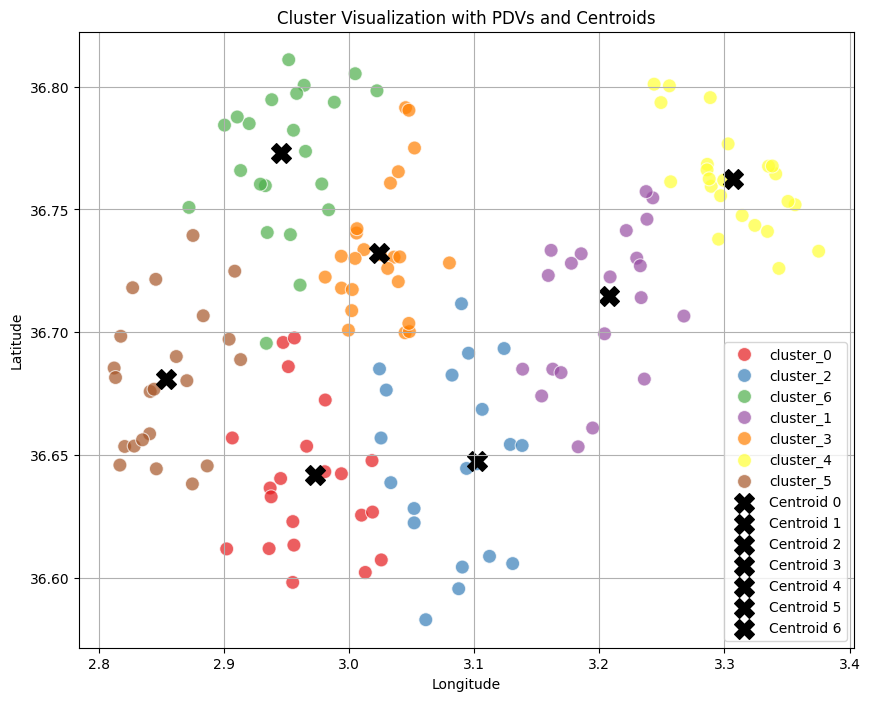

In [196]:
import json
import copy
from math import radians, sin, cos, sqrt, atan2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

threshold = 20

# ------------------ [HAVERSINE FUNCTION] ------------------
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometers
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return R * c

# ------------------ [LOAD PREVIOUS DATA] ------------------
with open("initial_clusters.json", "r", encoding="utf-8") as f:
    cluster_data = json.load(f)

with open("best_workload_parameters.json", "r", encoding="utf-8") as f:
    best_params = json.load(f)

alpha = best_params['best_alpha']
beta = best_params['best_beta']

# Flatten all PDVs
all_pdvs = []
for cid, cluster in cluster_data.items():
    for pdv in cluster['pdvs']:
        pdv['cluster'] = int(cid.split("_")[1])  
        all_pdvs.append(pdv)

centroids = {
    int(cid.split("_")[1]): (c['centroid']['latitude'], c['centroid']['longitude'])
    for cid, c in cluster_data.items()
}

# ------------------ [GROUP PDVs BY CLUSTER] ------------------
def group_pdvs_by_cluster(pdv_list):
    grouped = {}
    for pdv in pdv_list:
        c = pdv['cluster']
        if c not in grouped:
            grouped[c] = []
        grouped[c].append(pdv)
    return grouped

# ------------------ [COMPUTE CLUSTER STATS] ------------------
def compute_cluster_stats(grouped):
    stats = []
    for cid, pdvs in grouped.items():
        lat, lon = centroids[cid]
        dists = [haversine(lat, lon, pdv['latitude'], pdv['longitude']) for pdv in pdvs]
        avg_dist = sum(dists) / len(dists) if dists else 0
        workload = alpha * avg_dist + beta * len(pdvs)
        stats.append(workload)
    return stats

# ------------------ [COMPUTE INITIAL VARIANCE] ------------------
def compute_initial_variance(all_pdvs):
    initial_grouped = group_pdvs_by_cluster(all_pdvs)
    initial_workloads = compute_cluster_stats(initial_grouped)
    initial_variance = np.var(initial_workloads)
    return initial_variance

# ------------------ [PHASE 1: DISJOINT ASSIGNMENT] ------------------
def assign_to_nearest_centroid(all_pdvs):
    assigned = []
    for pdv in all_pdvs:
        min_dist = float('inf')
        nearest_cluster = None
        for cid, (clat, clon) in centroids.items():
            dist = haversine(pdv['latitude'], pdv['longitude'], clat, clon)
            if dist < min_dist:
                min_dist = dist
                nearest_cluster = cid
        pdv['cluster'] = nearest_cluster
        assigned.append(pdv)
    return assigned

# ------------------ [PHASE 2: BALANCE REFINEMENT] ------------------
def try_rebalance(all_pdvs, epsilon=2):
    print(f"\n[PHASE 1] Assigning PDVs to closest centroid...")
    pdvs = assign_to_nearest_centroid(copy.deepcopy(all_pdvs))

    print(f"[PHASE 2] Balancing workload with ε = {epsilon} km threshold...")
    improved = True

    while improved:
        improved = False
        grouped = group_pdvs_by_cluster(pdvs)
        current_variance = np.var(compute_cluster_stats(grouped))

        for pdv in pdvs:
            original_cluster = pdv['cluster']
            original_centroid = centroids[original_cluster]
            original_dist = haversine(pdv['latitude'], pdv['longitude'], *original_centroid)

            for new_cluster, new_centroid in centroids.items():
                if new_cluster == original_cluster:
                    continue
                new_dist = haversine(pdv['latitude'], pdv['longitude'], *new_centroid)

                if new_dist - original_dist > epsilon:
                    continue  # disjointness: don’t move if it's significantly farther

                # Try temporary reassignment
                pdv['cluster'] = new_cluster
                grouped_temp = group_pdvs_by_cluster(pdvs)
                new_variance = np.var(compute_cluster_stats(grouped_temp))

                if new_variance < current_variance:
                    improved = True
                    current_variance = new_variance
                    break
                else:
                    pdv['cluster'] = original_cluster

    return pdvs, current_variance

# ------------------ [RUN REBALANCE] ------------------
initial_variance = compute_initial_variance(all_pdvs)
print(f"Initial variance: {round(initial_variance, 4)}")

rebalanced_pdvs, final_variance = try_rebalance(all_pdvs)
rebalanced_clusters = group_pdvs_by_cluster(rebalanced_pdvs)

# ------------------ [SAVE TO JSON] ------------------
rebalanced_json = {}
for cid, pdvs in rebalanced_clusters.items():
    lat, lon = centroids[cid]
    avg_dist = sum(haversine(lat, lon, pdv['latitude'], pdv['longitude']) for pdv in pdvs) / len(pdvs)
    rebalanced_json[f"cluster_{cid}"] = {
        "centroid": {"latitude": lat, "longitude": lon},
        "avg_distance_km": avg_dist,
        "num_of_pdvs": len(pdvs),
        "pdvs": pdvs
    }

with open("rebalanced_clusters.json", "w", encoding="utf-8") as f:
    json.dump(rebalanced_json, f, ensure_ascii=False, indent=4)

print(f" >> Rebalanced clusters saved to 'rebalanced_clusters.json'")
print(f"New variance {round(final_variance, 4)}")

# ------------------ [PRINT WORKLOAD SUMMARY TABLE] ------------------
print("\nCluster    Num of PDVs     Avg Distance (km)     Workload (%)")
print("-" * 50)

grouped_final = group_pdvs_by_cluster(rebalanced_pdvs)
workloads = []
total_workload = 0

# Compute raw workloads and distances
for cid, pdvs in grouped_final.items():
    lat, lon = centroids[cid]
    dists = [haversine(lat, lon, pdv['latitude'], pdv['longitude']) for pdv in pdvs]
    avg_dist = sum(dists) / len(dists) if dists else 0
    workload = alpha * avg_dist + beta * len(pdvs)
    workloads.append((cid, len(pdvs), avg_dist, workload))
    total_workload += workload
    workload_values = [w for _, _, _, w in workloads]
    workload_difference = max(workload_values) - min(workload_values)

# Normalize and print
for cid, count, avg_dist, workload in workloads:
    percentage = (workload / total_workload) * 100
    print(f"Cluster {cid:<2}  {count:<14}  {avg_dist:<20.2f}  {percentage:.2f}")

print("-" * 50)
print(f"Total workload percentage: {sum((w / total_workload) * 100 for _, _, _, w in workloads):.2f}%")
print(f"\n Workload balance is acceptable: (Max workload - Min workload = {round(workload_difference, 4)}) is below the threshold ({threshold})")

# ------------------ [VISUALIZATION] ------------------
visualize_clusters(centroids, rebalanced_json)

## Dynamically Update Zones When New PDVs Are Added


> ### 1. Check if the new PDV is within wilaya boundaries
> - <u>Yes</u>: Go ahead with the cluster assignment process.
> - <u>No</u>: Skip the PDV — it’s outside the manager’s operating zone.
> ### 2. PDV Assignment
> - **Calculate ERROR**: `ERROR = max_workload - min_workload`
> - Fix a threshold for rebalancing (for now 20%).
> ### 3. If Workload > Threshold
> - Find the **farthest PDV** from the overloaded cluster’s centroid.
> - For each remaining cluster (ordered by proximity to that PDV):
>   - Try assigning the farthest PDV to this new cluster.
>   - Check if the move reduces the original cluster's workload **below the threshold**:
>     - <u>Yes</u>: Confirm the move and break the loop.
>     - <u>No</u>: Try the next nearest cluster.
> - Repeat until the cluster’s workload falls within acceptable range.
> ### 4. Recalculate Statistics After Reassignment
> - Update the cluster data:
>   - The number of PDVs in each cluster.
>   - The average distance to the cluster centroid.
>   - The workload using the formula:  
>     `workload = α × avg_distance_To_centroid + β × number_of_pdvs`
> ### 6. Save the updated results
> - Add the new PDV(s) to the correct cluster in your JSON data.
> - Update and save updated data in new data


 PDV is within the wilaya range.

 >> Workload stats BEFORE adding new PDV:
 - Variance: 4.2218
 - Max - Min: 6.4337

 >> After assigning PDV (before rebalancing):
 - Variance: 7.6874
 - Max - Min: 8.9900
!!  Imbalance detected. Rebalancing required...
 >> No improvement after full rebalance cycle. Reverting to original clusters.

 >> After rebalancing:
 - Variance: 7.6874
 - Max - Min: 8.9900
 New PDV assigned to cluster_3

 Final Cluster Stats
Cluster    Num of PDVs     Avg Distance (km)     Workload (%)
--------------------------------------------------
cluster_0  21              4.19               13.81          
cluster_2  20              4.92               13.57          
cluster_6  22              4.02               14.30          
cluster_1  21              4.30               13.86          
cluster_3  25              3.16               15.61          
cluster_4  23              3.41               14.59          
cluster_5  22              3.93               14.26          
---

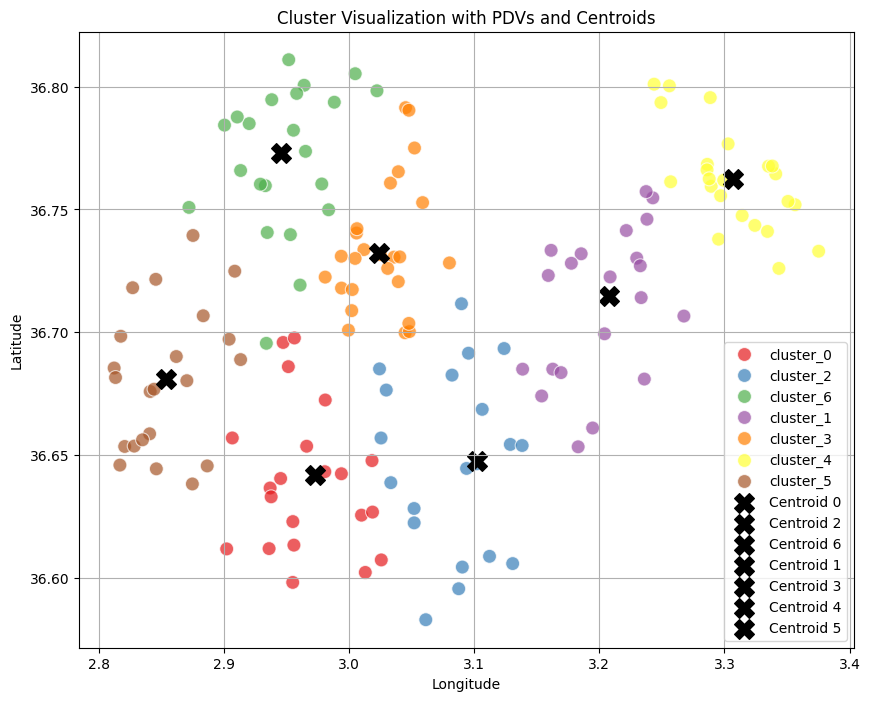

In [197]:
import json
import pandas as pd
from math import radians, sin, cos, sqrt, atan2
import numpy as np
import copy

threshold = 8

# ------------------ [LOAD PREVIOUS DATA] ------------------
df_cleaned = pd.read_csv("cleaned_pdv_data.csv")

with open("rebalanced_clusters.json", "r", encoding="utf-8") as f:
    rebalanced_clusters = json.load(f)

with open("best_workload_parameters.json", "r", encoding="utf-8") as f:
    best_params = json.load(f)

alpha = best_params['best_alpha']
beta = best_params['best_beta']

centroids = {
    int(cid.split('_')[1]): (
        cluster_data["centroid"]["latitude"],
        cluster_data["centroid"]["longitude"]
    )
    for cid, cluster_data in rebalanced_clusters.items()
}

# ------------------ [DEFINE NEW PDV DATA] ------------------
new_pdv = {
    "latitude": 36.7528,
    "longitude": 3.0588,
    "cluster": None,
}

# ------------------ [DEFINE WILAYA BOUNDARIES] ------------------
wilaya_boundaries = (36.0, 37.0, 2.5, 4.0)

# ------------------ [HELPER FUNCTIONS] ------------------

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return R * c

def euclidean_distance(pdv, centroid):
    return sqrt((pdv["latitude"] - centroid[0])**2 + (pdv["longitude"] - centroid[1])**2)

def compute_workloads(clusters, alpha=alpha, beta=beta):
    workloads = []
    for cluster in clusters.values():
        workload = alpha * cluster["avg_distance_km"] + beta * cluster["num_of_pdvs"]
        workloads.append(workload)
    return workloads

def is_within_wilaya(pdv, wilaya_boundaries):
    lat_min, lat_max, lon_min, lon_max = wilaya_boundaries
    return lat_min <= pdv["latitude"] <= lat_max and lon_min <= pdv["longitude"] <= lon_max

def update_cluster_stats(cluster_key, cluster_data):
    pdvs = cluster_data[cluster_key]["pdvs"]
    centroid = cluster_data[cluster_key]["centroid"]
    total_distance = sum(
        haversine(pdv['latitude'], pdv['longitude'], centroid["latitude"], centroid["longitude"])
        for pdv in pdvs
    )
    avg_distance = total_distance / len(pdvs) if pdvs else 0
    cluster_data[cluster_key]["avg_distance_km"] = avg_distance
    cluster_data[cluster_key]["num_of_pdvs"] = len(pdvs)

def update_centroids(clusters):
    new_centroids = {}
    for cid_str, cluster in clusters.items():
        cid = int(cid_str.split("_")[1])
        pdvs = cluster["pdvs"]
        if pdvs:
            avg_lat = sum(p["latitude"] for p in pdvs) / len(pdvs)
            avg_lon = sum(p["longitude"] for p in pdvs) / len(pdvs)
        else:
            avg_lat, avg_lon = cluster["centroid"]["latitude"], cluster["centroid"]["longitude"]
        cluster["centroid"]["latitude"] = avg_lat
        cluster["centroid"]["longitude"] = avg_lon
        new_centroids[cid] = (avg_lat, avg_lon)
    return new_centroids

# ------------------ [REBALANCING FUNCTION] ------------------

def rebalance_cluster(clusters, cluster_workloads, cluster_centroids, threshold):
    initial_clusters = copy.deepcopy(clusters)
    improved = False

    while True:
        workloads = compute_workloads(clusters)
        variance = np.var(workloads)
        max_wl = max(workloads)
        min_wl = min(workloads)

        if (max_wl - min_wl) <= threshold:
            break

        overloaded_index = workloads.index(max_wl)
        overloaded_key = f"cluster_{overloaded_index}"
        overloaded_centroid = cluster_centroids[overloaded_index]
        pdvs = clusters[overloaded_key]["pdvs"]

        if not pdvs:
            break

        farthest_pdv = max(
            pdvs,
            key=lambda pdv: euclidean_distance(pdv, overloaded_centroid)
        )
        dist_to_current = euclidean_distance(farthest_pdv, overloaded_centroid)

        possible_moves = [
            (i, euclidean_distance(farthest_pdv, centroid))
            for i, centroid in cluster_centroids.items()
            if i != overloaded_index and euclidean_distance(farthest_pdv, centroid) < dist_to_current
        ]

        if not possible_moves:
            break

        nearest_cluster_idx = min(possible_moves, key=lambda x: x[1])[0]
        target_key = f"cluster_{nearest_cluster_idx}"

        clusters[overloaded_key]["pdvs"].remove(farthest_pdv)
        clusters[target_key]["pdvs"].append(farthest_pdv)

        update_cluster_stats(overloaded_key, clusters)
        update_cluster_stats(target_key, clusters)
        cluster_centroids = update_centroids(clusters)

        new_workloads = compute_workloads(clusters)
        new_variance = np.var(new_workloads)

        if new_variance < variance:
            improved = True
        else:
            clusters[target_key]["pdvs"].remove(farthest_pdv)
            clusters[overloaded_key]["pdvs"].append(farthest_pdv)
            update_cluster_stats(overloaded_key, clusters)
            update_cluster_stats(target_key, clusters)
            cluster_centroids = update_centroids(clusters)
            break

    if not improved:
        print(" >> No improvement after full rebalance cycle. Reverting to original clusters.")
        clusters.clear()
        clusters.update(initial_clusters)

# ------------------ [ASSIGN NEW PDV TO CLUSTER] ------------------

def assign_pdv_to_cluster(new_pdv, centroids, clusters, alpha, beta, threshold):
    def initial_nearest_cluster(pdv, centroids):
        return min(
            centroids.items(),
            key=lambda item: haversine(pdv["latitude"], pdv["longitude"], item[1][0], item[1][1])
        )[0]

    pre_workloads = compute_workloads(clusters)
    print("\n >> Workload stats BEFORE adding new PDV:")
    print(f" - Variance: {np.var(pre_workloads):.4f}")
    print(f" - Max - Min: {max(pre_workloads) - min(pre_workloads):.4f}")

    best_cluster = initial_nearest_cluster(new_pdv, centroids)
    new_pdv["cluster"] = best_cluster
    cluster_key = f"cluster_{best_cluster}"
    clusters[cluster_key]["pdvs"].append(new_pdv)
    update_cluster_stats(cluster_key, clusters)

    post_assign_workloads = compute_workloads(clusters)
    print("\n >> After assigning PDV (before rebalancing):")
    print(f" - Variance: {np.var(post_assign_workloads):.4f}")
    print(f" - Max - Min: {max(post_assign_workloads) - min(post_assign_workloads):.4f}")

    if max(post_assign_workloads) - min(post_assign_workloads) > threshold:
        print("!!  Imbalance detected. Rebalancing required...")
        updated_centroids = update_centroids(clusters)
        rebalance_cluster(clusters, post_assign_workloads, updated_centroids, threshold)

        post_rebalance_workloads = compute_workloads(clusters)
        print("\n >> After rebalancing:")
        print(f" - Variance: {np.var(post_rebalance_workloads):.4f}")
        print(f" - Max - Min: {max(post_rebalance_workloads) - min(post_rebalance_workloads):.4f}")
    else:
        print(" Workload within threshold. No rebalancing needed.")

    return new_pdv

# ------------------ [MAIN LOGIC] ------------------

if is_within_wilaya(new_pdv, wilaya_boundaries):
    print(" PDV is within the wilaya range.")
    updated_pdv = assign_pdv_to_cluster(new_pdv, centroids, rebalanced_clusters, alpha, beta, threshold)
    cluster_id = updated_pdv["cluster"]
    print(f" New PDV assigned to cluster_{cluster_id}")
else:
    print(" PDV is outside of the managed wilaya. Skipping.")

# ------------------ [DISPLAY FINAL STATS] ------------------

print("\n Final Cluster Stats")
print("Cluster    Num of PDVs     Avg Distance (km)     Workload (%)")
print("--------------------------------------------------")

workload_values = {
    cid: alpha * cluster["avg_distance_km"] + beta * cluster["num_of_pdvs"]
    for cid, cluster in rebalanced_clusters.items()
}
sum_workload = sum(workload_values.values())

for cid, cluster in rebalanced_clusters.items():
    num_pdvs = cluster["num_of_pdvs"]
    avg_distance = cluster["avg_distance_km"]
    workload = workload_values[cid]
    workload_percentage = (workload / sum_workload) * 100
    print(f"{cid:<10} {num_pdvs:<15} {avg_distance:<18.2f} {workload_percentage:<15.2f}")

print("--------------------------------------------------")
print(f" Total workload percentage: 100.00%")

# ------------------ [SAVE RESULT] ------------------

with open("rebalanced_add_clusters.json", "w", encoding="utf-8") as f:
    json.dump(rebalanced_clusters, f, ensure_ascii=False, indent=4)

print("\n New PDV added and clusters saved with rebalancing (if needed).")


visualize_clusters(centroids, rebalanced_clusters)


## Dynamically Update Zones When PDVs Are Deleted

### 4. **Delete a Specific PDV:**
   - **Identify the PDV**: We begin by pinpointing the specific PDV that needs to be deleted using its **latitude** and **longitude**.
   - **Find the Cluster**: Once we identify the PDV, we locate the cluster it belongs to based on its geographical position.
   - **Remove the PDV**: After confirming its location within the cluster, the PDV is removed from the cluster’s list of PDVs.
   - **Update Cluster Statistics**: Once the PDV is deleted, we need to update the statistics of the cluster. This includes recalculating the cluster’s **average distance** and **workload**.

### 5. **Rebalance (Optional):**
   - **Find Closest PDV**: We look for the **closest PDV** to the centroid of the cluster where a PDV was removed "from other cluster".
   - **Move the PDV**: Once the closest PDV is identified, we assign it to another cluster that is **nearest** based on its centroid.
     - The centroid of a cluster is calculated by averaging the **latitude** and **longitude** of all PDVs within the cluster.
   - **Update Both Clusters**: After moving the PDV to the new cluster, we update the statistics of both clusters — the original cluster and the new one that received the PDV.



In [198]:
import json
import statistics
from math import radians, cos, sin, asin, sqrt

# ------------------ [HAVERSINE FUNCTION] ------------------
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    d_lat = radians(lat2 - lat1)
    d_lon = radians(lon2 - lon1)
    a = sin(d_lat / 2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(d_lon / 2)**2
    c = 2 * asin(sqrt(a))
    return R * c

# ------------------ [UPDATE CLUSTER STATS] ------------------
def update_cluster_stats(cluster_key, clusters):
    cluster = clusters[cluster_key]
    pdvs = cluster["pdvs"]
    if not pdvs:
        cluster["avg_distance_km"] = 0.0
        cluster["num_of_pdvs"] = 0
        return
    center_lat = sum(p["latitude"] for p in pdvs) / len(pdvs)
    center_lon = sum(p["longitude"] for p in pdvs) / len(pdvs)
    distances = [haversine(p["latitude"], p["longitude"], center_lat, center_lon) for p in pdvs]
    cluster["avg_distance_km"] = sum(distances) / len(distances)
    cluster["num_of_pdvs"] = len(pdvs)

# ------------------ [CALCULATE VARIANCE] ------------------
def calculate_workload_variance(clusters, alpha, beta):
    workloads = [
        alpha * c["avg_distance_km"] + beta * c["num_of_pdvs"]
        for c in clusters.values()
    ]
    total = sum(workloads)
    if total == 0:
        return 0.0
    percentages = [(w / total) * 100 for w in workloads]
    return statistics.variance(percentages)

# ------------------ [WORKLOAD DIFF] ------------------
def workload_diff_percent(clusters, alpha, beta):
    workloads = {
        cid: alpha * c["avg_distance_km"] + beta * c["num_of_pdvs"]
        for cid, c in clusters.items()
    }
    total = sum(workloads.values())
    if total == 0:
        return 0.0, 0.0, 0.0  # max, min, diff
    percentages = {cid: (w / total) * 100 for cid, w in workloads.items()}
    max_p = max(percentages.values())
    min_p = min(percentages.values())
    return max_p, min_p, max_p - min_p

# ------------------ [LOAD FILES] ------------------
with open("rebalanced_add_clusters.json", "r", encoding="utf-8") as f:
    rebalanced_clusters = json.load(f)

with open("best_workload_parameters.json", "r", encoding="utf-8") as f:
    best_params = json.load(f)

alpha = best_params['best_alpha']
beta = best_params['best_beta']

# ------------------ [BEFORE DELETION] ------------------
variance_before = calculate_workload_variance(rebalanced_clusters, alpha, beta)
max_before, min_before, diff_before = workload_diff_percent(rebalanced_clusters, alpha, beta)
print(">> Workload stats BEFORE deleting PDV:")
print(f" - Variance: {variance_before:.4f}")
print(f" - Max - Min: {diff_before:.4f}")

# ------------------ [DELETE PDV] ------------------
pdv_to_delete = {"latitude": 36.7528, "longitude": 3.0588}

deleted = False
deleted_cluster_key = None
for cluster_key, cluster in rebalanced_clusters.items():
    pdvs = cluster["pdvs"]
    for pdv in pdvs:
        if (abs(pdv["latitude"] - pdv_to_delete["latitude"]) < 1e-6 and
            abs(pdv["longitude"] - pdv_to_delete["longitude"]) < 1e-6):
            pdvs.remove(pdv)
            update_cluster_stats(cluster_key, rebalanced_clusters)
            deleted = True
            deleted_cluster_key = cluster_key
            print(f"\n >> Deleted target PDV from {cluster_key}")
            break
    if deleted:
        break

if not deleted:
    print("\n PDV not found.")
else:
    variance_after_delete = calculate_workload_variance(rebalanced_clusters, alpha, beta)
    max_p, min_p, diff = workload_diff_percent(rebalanced_clusters, alpha, beta)
    print("\n >> After deletion (before rebalancing):")
    print(f" - Variance: {variance_after_delete:.4f}")
    print(f" - Max - Min: {diff:.4f}")

    if diff >= 10:
        print("!!  Imbalance detected. Rebalancing required...\n")

    # ------------------ [REBALANCE] ------------------
    while diff >= 10:
        target_pdvs = rebalanced_clusters[deleted_cluster_key]["pdvs"]
        if not target_pdvs:
            break
        target_center_lat = sum(p["latitude"] for p in target_pdvs) / len(target_pdvs)
        target_center_lon = sum(p["longitude"] for p in target_pdvs) / len(target_pdvs)

        best_pdv = None
        best_distance = float('inf')
        best_donor_cluster = None

        for donor_key, donor in rebalanced_clusters.items():
            if donor_key == deleted_cluster_key or len(donor["pdvs"]) < 2:
                continue
            for pdv in donor["pdvs"]:
                dist = haversine(pdv["latitude"], pdv["longitude"], target_center_lat, target_center_lon)
                if dist < best_distance:
                    best_distance = dist
                    best_pdv = pdv
                    best_donor_cluster = donor_key

        if best_pdv and best_donor_cluster:
            rebalanced_clusters[best_donor_cluster]["pdvs"].remove(best_pdv)
            rebalanced_clusters[deleted_cluster_key]["pdvs"].append(best_pdv)
            update_cluster_stats(best_donor_cluster, rebalanced_clusters)
            update_cluster_stats(deleted_cluster_key, rebalanced_clusters)
            print(f" >> Transferred PDV from {best_donor_cluster} >>> {deleted_cluster_key}")
        else:
            break

        max_p, min_p, diff = workload_diff_percent(rebalanced_clusters, alpha, beta)

    variance_after_rebalancing = calculate_workload_variance(rebalanced_clusters, alpha, beta)
    print("\n >> After rebalancing:")
    print(f" - Variance: {variance_after_rebalancing:.4f}")
    print(f" - Max - Min: {diff:.4f}")
    if diff < 10:
        print(">>  Workload balance is ACCEPTABLE")
    else:
        print(">>  Workload balance is NOT acceptable (difference >= 10)")

# ------------------ [FINAL WORKLOAD TABLE] ------------------
print("\n Final Cluster Workloads")
print("Cluster    Num of PDVs     Avg Distance (km)     Workload (%)")
print("---------------------------------------------------------------")

workload_values = {
    cid: alpha * cluster["avg_distance_km"] + beta * cluster["num_of_pdvs"]
    for cid, cluster in rebalanced_clusters.items()
}
sum_workload = sum(workload_values.values())
total_workload = 0

for cid, cluster in rebalanced_clusters.items():
    num_pdvs = cluster["num_of_pdvs"]
    avg_distance = cluster["avg_distance_km"]
    workload = workload_values[cid]
    workload_percentage = (workload / sum_workload) * 100 if sum_workload > 0 else 0
    total_workload += workload_percentage
    print(f"{cid:<10} {num_pdvs:<15} {avg_distance:<18.2f} {workload_percentage:<15.2f}")

print("---------------------------------------------------------------")
print(f" Total workload percentage: {total_workload:.2f}%")

# ------------------ [SAVE RESULT] ------------------
with open("rebalanced_delete_clusters.json", "w", encoding="utf-8") as f:
    json.dump(rebalanced_clusters, f, ensure_ascii=False, indent=4)


>> Workload stats BEFORE deleting PDV:
 - Variance: 0.4614
 - Max - Min: 2.0392

 >> Deleted target PDV from cluster_3

 >> After deletion (before rebalancing):
 - Variance: 0.2586
 - Max - Min: 1.4759

 >> After rebalancing:
 - Variance: 0.2586
 - Max - Min: 1.4759
>>  Workload balance is ACCEPTABLE

 Final Cluster Workloads
Cluster    Num of PDVs     Avg Distance (km)     Workload (%)
---------------------------------------------------------------
cluster_0  21              4.19               13.89          
cluster_2  20              4.92               13.65          
cluster_6  22              4.02               14.38          
cluster_1  21              4.30               13.94          
cluster_3  24              3.15               15.13          
cluster_4  23              3.41               14.67          
cluster_5  22              3.93               14.34          
---------------------------------------------------------------
 Total workload percentage: 100.00%


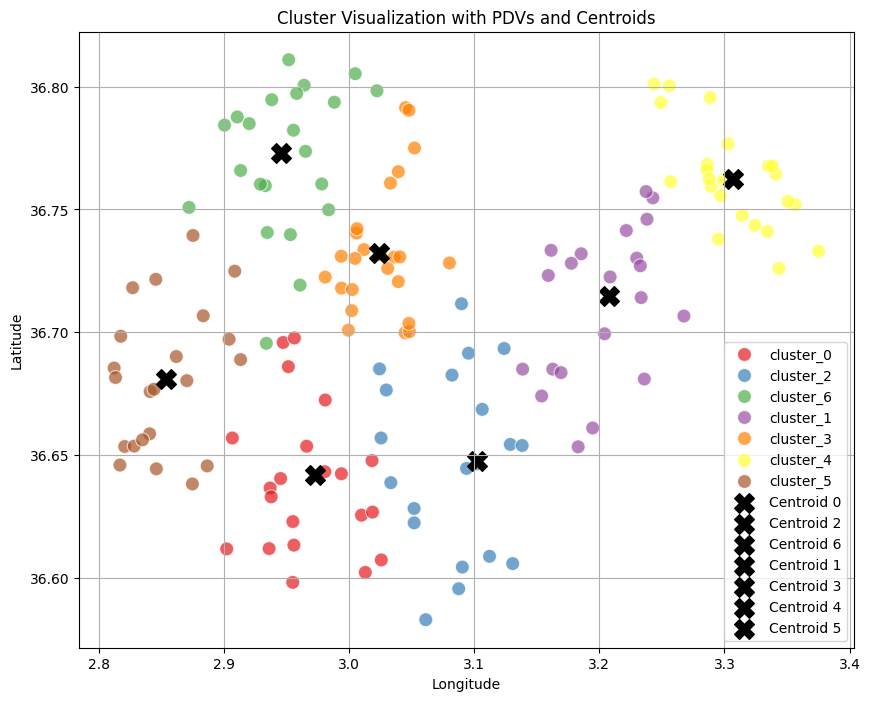

In [199]:
visualize_clusters(centroids, rebalanced_clusters)